# Week 6 - Bivariate Analysis, part 2

# 1. Lesson: no lesson this week

# 2. Weekly graph question

Suppose you wanted to show the nitrate and phosphate level in a water sample.  What are the advantages and disadvantages of showing this as an area plot, as opposed to two separate line graphs?  How would you adjust the graphs shown to improve the presentation?

In [2]:
import numpy as np
import seaborn as sns
import pandas as pd

Text(0, 0.5, 'Nitrate level (% of eutrophic value)')

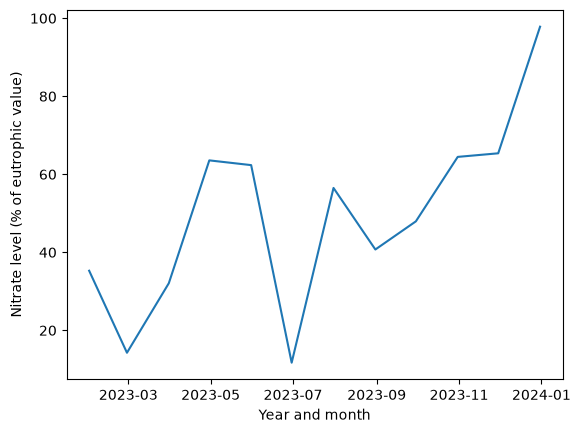

In [4]:
numdates = 12
np.random.seed(0)
time_series = 100 * (np.random.normal(size = numdates) / 5 + np.arange(numdates) / 16)
datearray = pd.date_range(start='2023/01/01', end='2024/01/01', freq='ME')
ax = sns.lineplot(x = datearray, y = time_series)
ax.set_xlabel("Year and month")
ax.set_ylabel("Nitrate level (% of eutrophic value)")

Text(0, 0.5, 'Phosphate level (% of eutrophic value)')

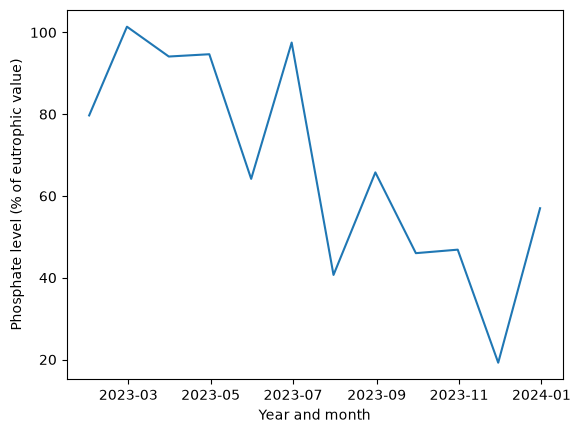

In [5]:
np.random.seed(1)
time_series_2 =  100 * (1 - (np.random.normal(size = numdates) / 8 + np.arange(numdates) / 16))
datearray = pd.date_range(start='2023/01/01', end='2024/01/01', freq='ME')
ax = sns.lineplot(x = datearray, y = time_series_2)
ax.set_xlabel("Year and month")
ax.set_ylabel("Phosphate level (% of eutrophic value)")

<Axes: >

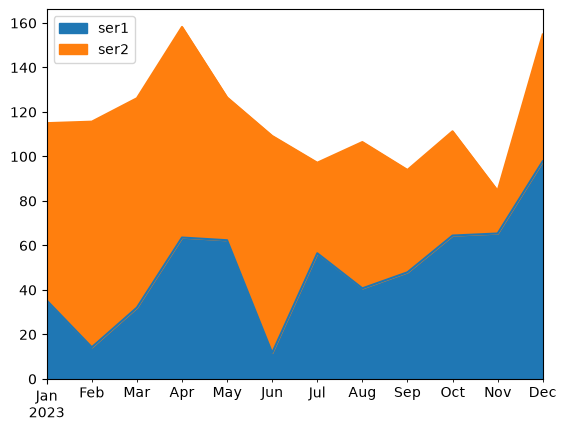

In [6]:
df = pd.DataFrame({'ser1': time_series, 'ser2': time_series_2}, index = datearray)
df.plot.area()

An area plot makes it easier to compare the nitrate and phosphate levels in one graph and see how both change over time. It also uses less space than showing two separate line graphs. However, a stacked area plot can make the individual values harder to read because the second series is plotted on top of the first rather than from the same baseline. The two separate line graphs make each trend easier to see, but they require more space and make direct comparison a little harder. To improve the presentation, I would use clearer labels such as “Nitrate” and “Phosphate” instead of “ser1” and “ser2,” add a descriptive title, keep the same y-axis scale for comparison, simplify the date labels, and use a legend or direct labels to make the two series easier to identify.

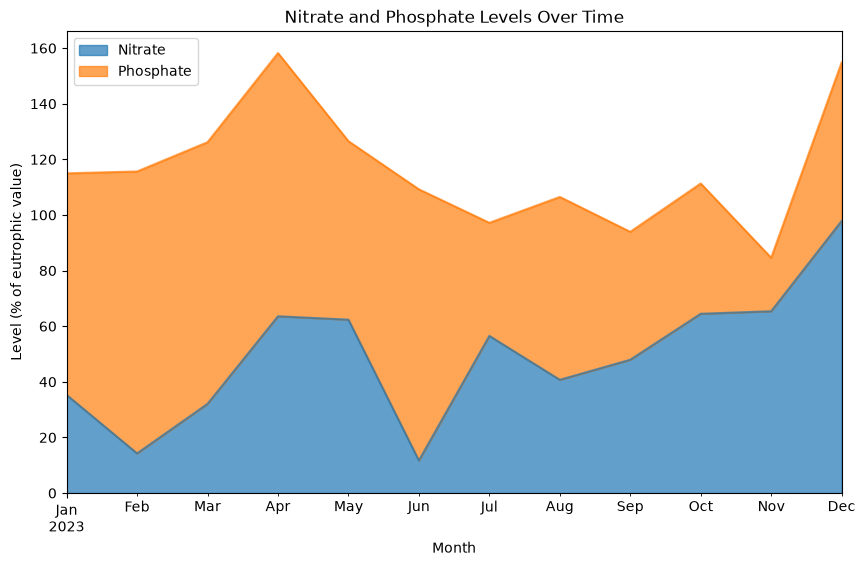

In [8]:
# Combine both time series into one DataFrame
# Using descriptive column names makes the legend easier to understand
import matplotlib.pyplot as plt

df = pd.DataFrame({
    "Nitrate": time_series,
    "Phosphate": time_series_2
}, index=datearray)

# Create the improved area plot
ax = df.plot.area(
    figsize=(10, 6),
    alpha=0.7
)

# Add a descriptive title and clear axis labels
ax.set_title("Nitrate and Phosphate Levels Over Time")
ax.set_xlabel("Month")
ax.set_ylabel("Level (% of eutrophic value)")

plt.show()

# 3. Working on your chosen project datasets this semester

This week, you will do the same types of exercises as last week, but you should use your chosen datasets that someone in your class found last semester. (They likely will not be the particular datasets that you found yourself.)

### Here are some types of analysis you can do:

- Find correlations between pairs of variables.

- Draw scatterplots, especially when the correlation is large.

- Draw pairplots.

- Draw line graphs and/or area graphs when there is date or time data together with numerical data.

### Conclusions:

- Explain what conclusions you would draw from this analysis: are the data what you expect?  Are the data likely to be usable?  If the data are not useable, find some new data!

- Do you see any outliers?  (Data points that are far from the rest of the data).

- Are any data items highly correlated with each other, suggesting that they are redundant?

- For the line plots, do you see a trend or pattern over time?  Does this suggest that the data are changing over time (drifting) in such a way as to invalidate comparisons?

- Can you think of any confounding variables?  (Third variables that could explain any correlations between other variables.  These third variables may or may not be reported in the dataset.)

In [9]:
# Libraries needed for the analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the diabetes dataset from the Week 2 data folder
df = pd.read_csv("../Week2/data/diabetes_012_health_indicators_BRFSS2015.csv")

# Display the first five rows
df.head()

,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [10]:
# Check the number of rows and columns
df.shape

(253680, 22)

In [11]:
# Select variables that may have meaningful relationships with diabetes
selected_cols = [
    "Diabetes_012",
    "BMI",
    "HighBP",
    "HighChol",
    "GenHlth",
    "PhysHlth",
    "Age",
    "Income"
]

# Create a smaller DataFrame containing the selected variables
df_selected = df[selected_cols]

df_selected.head()

,Diabetes_012,BMI,HighBP,HighChol,GenHlth,PhysHlth,Age,Income
0,0.0,40.0,1.0,1.0,5.0,15.0,9.0,3.0
1,0.0,25.0,0.0,0.0,3.0,0.0,7.0,1.0
2,0.0,28.0,1.0,1.0,5.0,30.0,9.0,8.0
3,0.0,27.0,1.0,0.0,2.0,0.0,11.0,6.0
4,0.0,24.0,1.0,1.0,2.0,0.0,11.0,4.0


In [12]:
# Calculate correlations between the selected variables
correlation_matrix = df_selected.corr()

# Display the correlation values
correlation_matrix.round(2)

,Diabetes_012,BMI,HighBP,HighChol,GenHlth,PhysHlth,Age,Income
Diabetes_012,1.00,0.22,0.27,0.21,0.30,0.18,0.19,-0.17
BMI,0.22,1.00,0.21,0.11,0.24,0.12,-0.04,-0.10
HighBP,0.27,0.21,1.00,0.30,0.30,0.16,0.34,-0.17
HighChol,0.21,0.11,0.30,1.00,0.21,0.12,0.27,-0.09
GenHlth,0.30,0.24,0.30,0.21,1.00,0.52,0.15,-0.37
PhysHlth,0.18,0.12,0.16,0.12,0.52,1.00,0.10,-0.27
Age,0.19,-0.04,0.34,0.27,0.15,0.10,1.00,-0.13
Income,-0.17,-0.10,-0.17,-0.09,-0.37,-0.27,-0.13,1.00


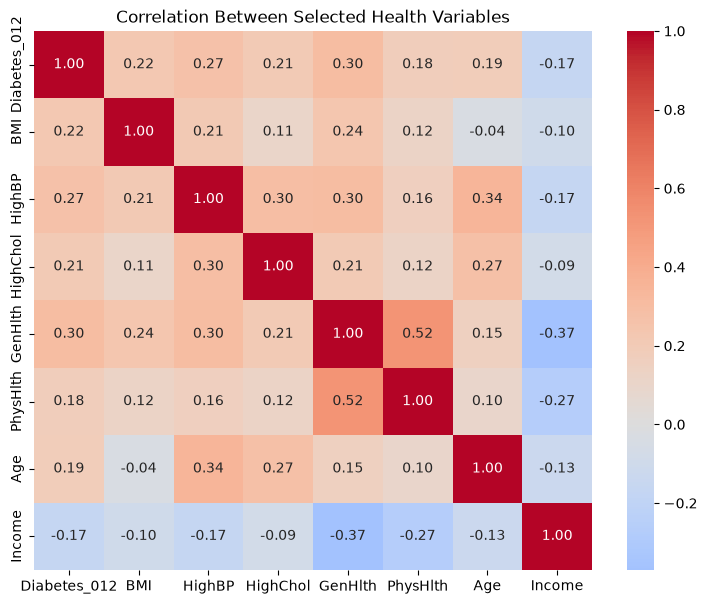

In [13]:
# Create a heatmap of the correlation matrix
plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Between Selected Health Variables")
plt.show()

In [14]:
# Sort variables by their correlation with diabetes status
diabetes_corr = (
    correlation_matrix["Diabetes_012"]
    .drop("Diabetes_012")
    .sort_values(ascending=False)
)

diabetes_corr

GenHlth     0.302587
HighBP      0.271596
BMI         0.224379
HighChol    0.209085
Age         0.185026
PhysHlth    0.176287
Income     -0.171483
Name: Diabetes_012, dtype: float64

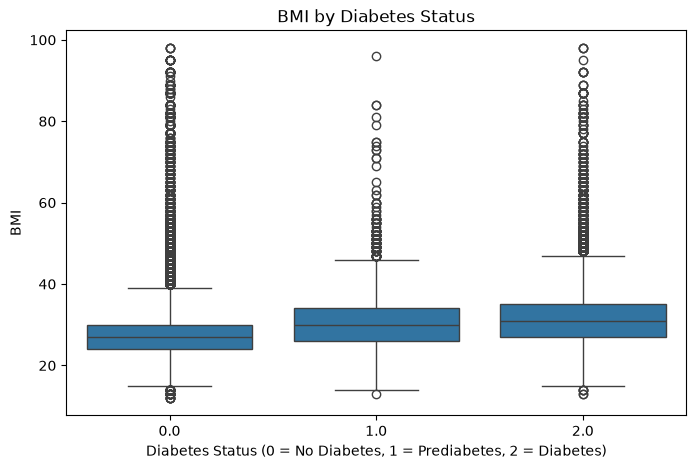

In [15]:
# Compare BMI distributions across diabetes-status groups
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Diabetes_012",
    y="BMI"
)

plt.title("BMI by Diabetes Status")
plt.xlabel("Diabetes Status (0 = No Diabetes, 1 = Prediabetes, 2 = Diabetes)")
plt.ylabel("BMI")
plt.show()

In [16]:
# Calculate the proportion of people with high blood pressure
# within each diabetes-status group
highbp_by_diabetes = (
    df.groupby("Diabetes_012")["HighBP"]
    .mean()
    .reset_index()
)

highbp_by_diabetes

,Diabetes_012,HighBP
0,0.0,0.371132
1,1.0,0.629022
2,2.0,0.752674


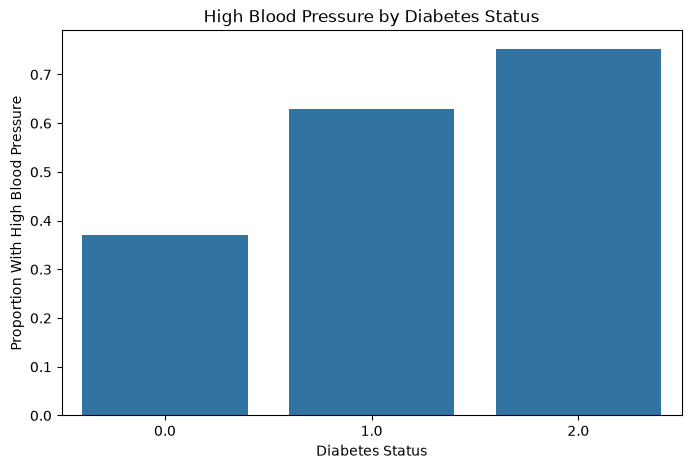

In [17]:
# Create a bar plot showing high blood pressure by diabetes status
plt.figure(figsize=(8, 5))

sns.barplot(
    data=highbp_by_diabetes,
    x="Diabetes_012",
    y="HighBP"
)

plt.title("High Blood Pressure by Diabetes Status")
plt.xlabel("Diabetes Status")
plt.ylabel("Proportion With High Blood Pressure")
plt.show()

In [18]:
# Calculate average coded age category for each diabetes group
age_by_diabetes = (
    df.groupby("Diabetes_012")["Age"]
    .mean()
    .reset_index()
)

age_by_diabetes

,Diabetes_012,Age
0,0.0,7.786559
1,1.0,9.083351
2,2.0,9.379053


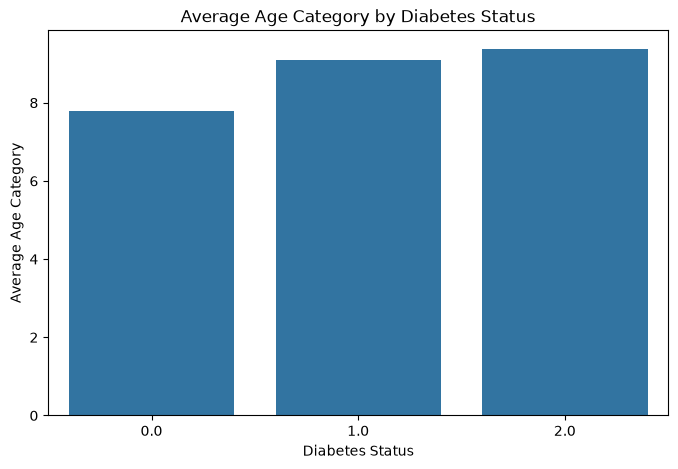

In [19]:
# Compare average age category across diabetes groups
plt.figure(figsize=(8, 5))

sns.barplot(
    data=age_by_diabetes,
    x="Diabetes_012",
    y="Age"
)

plt.title("Average Age Category by Diabetes Status")
plt.xlabel("Diabetes Status")
plt.ylabel("Average Age Category")
plt.show()

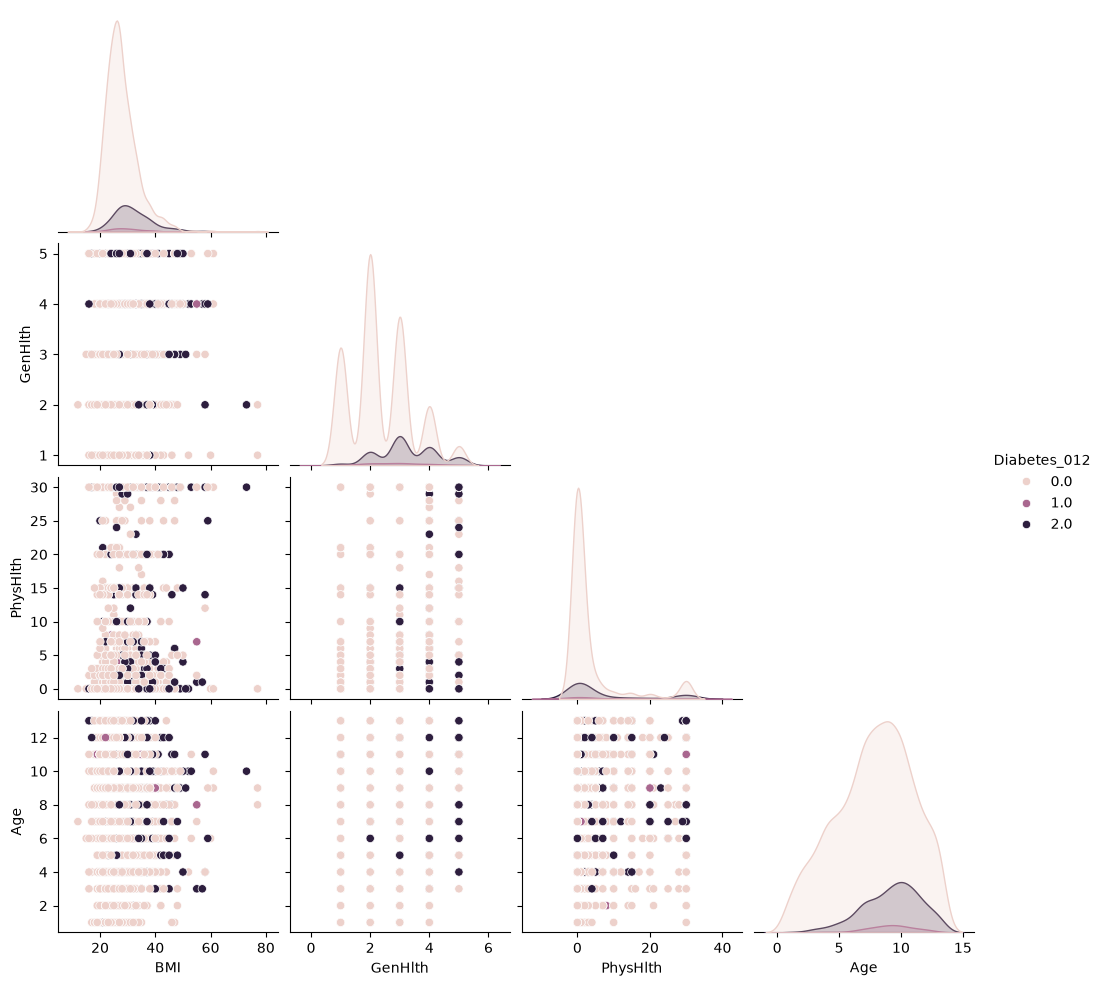

In [20]:
# Take a random sample to keep the pairplot readable and faster to generate
pairplot_data = df[
    ["Diabetes_012", "BMI", "GenHlth", "PhysHlth", "Age"]
].sample(n=3000, random_state=42)

# Create pairwise plots between selected variables
sns.pairplot(
    pairplot_data,
    hue="Diabetes_012",
    corner=True
)

plt.show()

Conclusions:
The bivariate analysis identified several relationships between health characteristics and diabetes status. General health had the strongest positive correlation with diabetes status at approximately 0.30, followed by high blood pressure at 0.27, BMI at 0.22, and high cholesterol at 0.21. Income showed a negative correlation of approximately -0.17. These correlations are not extremely strong, suggesting that diabetes status is associated with several factors rather than being explained by a single variable.
The individual plots support these findings. Median BMI increased across the no-diabetes, prediabetes, and diabetes groups. High blood pressure also became much more common as diabetes status increased, rising from approximately 37% among people without diabetes to about 63% among people with prediabetes and 75% among those with diabetes. The average coded age category also increased from 7.79 in the no-diabetes group to 9.08 in the prediabetes group and 9.38 in the diabetes group, suggesting that diabetes is more common among older respondents in this dataset.
The strongest correlation between predictor variables was between general health and physical health at approximately 0.52. Although these variables are related, the relationship is not strong enough to consider them completely redundant. The BMI boxplot also revealed several extreme values, including BMI values approaching 100. These should be considered potential outliers, but they should not automatically be removed because they may represent legitimate survey responses.
Overall, the dataset appears usable for further analysis. The pairplot does not show perfect separation between diabetes groups, which suggests that a combination of variables will likely be needed for prediction. Possible confounding variables include age, income, physical activity, general health, and other health conditions because they may influence both diabetes status and other predictors such as BMI and high blood pressure. The dataset does not contain a time variable, so trends over time and temporal drift cannot be evaluated.

# 4. Storytelling With Data plot

Reproduce any graph of your choice in p. 86-98 of the Storytelling With Data book as best you can.  (The second half of chapter three).  You do not have to get the exact data values right, just the overall look and feel.

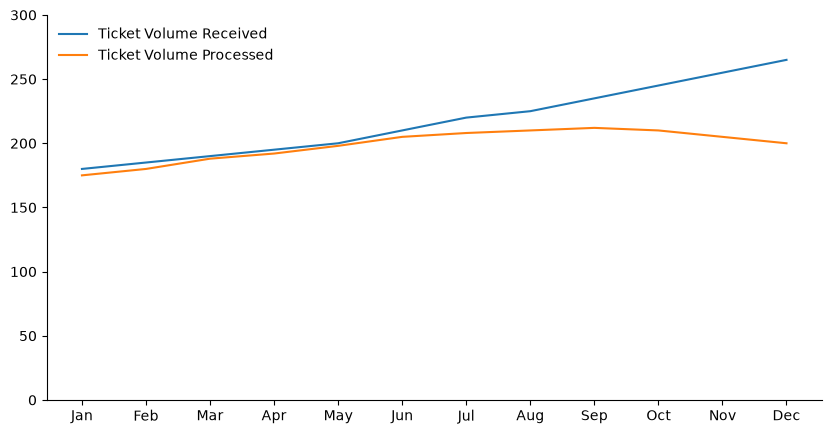

In [23]:
# Recreate Figure 3.21 from Storytelling With Data
# The goal is to show two monthly ticket-volume trends
# with simple, cleaned-up axis labels

import matplotlib.pyplot as plt

# Months shown in the original figure
months = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

# Approximate values to match the overall look and feel
received = [180, 185, 190, 195, 200, 210, 220, 225, 235, 245, 255, 265]
processed = [175, 180, 188, 192, 198, 205, 208, 210, 212, 210, 205, 200]

# Create the line plot
plt.figure(figsize=(10, 5))

plt.plot(months, received, label="Ticket Volume Received")
plt.plot(months, processed, label="Ticket Volume Processed")

# Clean up the chart to reduce clutter
plt.ylim(0, 300)
plt.yticks([0, 50, 100, 150, 200, 250, 300])

# Remove unnecessary gridlines
plt.grid(False)

# Remove the top and right chart borders
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Add legend
plt.legend(frameon=False)

plt.show()

I chose to recreate Figure 3.21 on page 95 of Storytelling With Data. This figure demonstrates how cleaning up axis labels can reduce visual clutter. The y-axis uses simple whole numbers instead of unnecessary decimal places, and the months are abbreviated so the labels can remain horizontal and easier to read.